# AutoPilotRL — Race day: a new circuit, more cars, and a video

The PPO driver of v5 learned on **one** circuit, with **one** slower car. Here we put it in a **race**:
- on a circuit it has **never seen** (or on the old one, if you prefer);
- against as many opponents as you choose;
- with a **video** of the race to watch and share.

## How the race works
- All the opponents start **ahead of us**, in a starting grid; we start last.
- The opponents are driven by highway-env's classic model (IDM for the speed, MOBIL for lane changes), each at its own speed, slower than ours.
- Our car drives at 10 m/s and only steers, as in v5. Optionally, a classical **safety brake** (not learned) slows it down when a car is right ahead in its path; see Step 3.
- **Position** in the race: we measure how far every car has gone along the track (laps included). Our position is 1 + the number of opponents ahead of us.
- **Winning** = being first when the time runs out, without crashing or leaving the road.

We are faster than everybody, so **the race is won by overtaking everyone without touching anyone**: exactly the skill learned in v5, but now in traffic and on new curves.

### What we learned from the first version of this notebook
With opponents at 7–9.5 m/s, a 60 s race and 30 m between opponents, the v5 driver never won (0 wins out of 20, 65% DNF), and 50,000 steps of fine-tuning did not change that:
- **The races were almost impossible to win.** We gained only 0.5–3 m/s on each opponent, so the last one (175 m ahead) was often out of reach before the end.
- **Overtakes happened in the worst places.** Catching up slowly means meeting the cars wherever they are, often in the S-bends.
- **Without brakes, every mistake was a crash.** A car slower than us right ahead in a curve leaves only two options: steer around it, or hit it.

The second version (slower opponents, safety brake) finished its best race in **3rd place** without crashing. The video showed a new problem: after gaining 4 places in 35 s, the car stayed **behind a slow car for almost a minute** at 5.4 m/s, held back by the brake, and never tried to pass.
- **Nothing in its reward asks it to overtake.** The v5 reward pays for staying in the lane centre and steering little. Following a slow car, held back by the brake, is a perfectly good way to collect that reward.
- It is the lesson of v4–v6 again: **the agent optimises the reward we wrote, not what we mean.** We want it to *race*, so the reward must say so. Step 5 adds a **racing reward**: speed, positions gained, and a penalty for crashing.

The new defaults:
- slower opponents (4.5–7.5 m/s), closer together (20 m);
- races of 90 s (about 1.6 laps);
- longer fine-tuning with a larger learning rate, the **racing reward**, and the brake active during training;
- an optional safety brake for the video;
- automatic choice of the best race of the series for the video.

## Plan
1. **Settings:** the only cell you need to edit (circuit, number of opponents, race duration, …).
2. The race: circuit geometry, starting grid, positions.
3. The v5 driver, loaded as it is: how well does it **transfer** to the new races? (*zero-shot*) And the **safety brake**.
4. **Fine-tuning:** PPO continues training from the v5 weights, on races like these.
5. A **series of 20 races** before and after fine-tuning, and with the safety brake: wins, positions, retirements.
6. The **highlight video**: simulator camera, track map with every car, live position.

**Before running:**
- `results/v5_ppo.pt` from v5 must be in the `results` folder next to this notebook.
- For an MP4 video (better to share than a GIF) install: `pip install imageio imageio-ffmpeg`. Without it, the notebook saves a GIF.

With the default settings the whole notebook takes about **35–45 minutes**, most of it fine-tuning. Run everything with **Run All**.

## Settings

| Setting | Meaning |
|---|---|
| `TRACK` | `"classic"`: the v5 circuit (2 lanes) · `"large"`: a longer circuit with 3 lanes and more curves · `"oval"`: an oval whose length and number of lanes you choose |
| `OVAL_LENGTH`, `OVAL_LANES` | Only for `"oval"`: length of the straights (m) and number of lanes (2–6) |
| `N_OPPONENTS` | Number of opponents on the starting grid |
| `OPPONENT_SPEED` | Range of the opponents' speeds (m/s); ours is 10 |
| `RACE_SECONDS` | Duration of a race |
| `HIGHLIGHT_SEED` | The race shown in the video: `"best"` picks the best race of the series (a win if there is one), or give a number for a specific race |
| `SAFETY_BRAKE` | `True`: the final driver (series and video) also uses the classical safety brake of Step 3 |
| `FINE_TUNE`, `FINE_TUNE_STEPS` | Whether to continue training on these races, and for how many steps |
| `SERIES_RACES` | Number of races used to measure the driver |
| `VIDEO_FORMAT` | `"mp4"` or `"gif"` |
| `REAL_TIME` | `False`: the video plays at twice real time (shorter); `True`: real time |

In [1]:
# --- SETTINGS (edit here) ---

# Circuit: "classic", "large" or "oval".
TRACK = "large"

# Oval only: length of the straights in metres.
OVAL_LENGTH = 150

# Oval only: number of lanes.
OVAL_LANES = 3

# Opponents on the starting grid.
N_OPPONENTS = 6

# Speed range of the opponents (m/s); ours is fixed at 10.
OPPONENT_SPEED = (4.5, 7.5)

# Duration of a race in seconds.
RACE_SECONDS = 90

# The race shown in the video: "best" (the best race of the series) or a number.
HIGHLIGHT_SEED = "best"

# Use the classical safety brake for the final driver (series and video)?
SAFETY_BRAKE = True

# Continue training on these races?
FINE_TUNE = True

# Environment steps of fine-tuning.
FINE_TUNE_STEPS = 80_000

# Races used to measure the driver.
SERIES_RACES = 20

# "mp4" or "gif".
VIDEO_FORMAT = "mp4"

# False: video at twice real time; True: real time.
REAL_TIME = False

In [2]:
# --- LIBRARIES ---

# Gymnasium: the standard interface for RL environments.
import gymnasium as gym

# Registers the highway-env environments.
import highway_env

# The opponents' driver model (IDM + MOBIL).
from highway_env.vehicle.behavior import IDMVehicle

# Numerical computing.
import numpy as np

# PyTorch: tensors and neural networks.
import torch

# Neural network layers.
import torch.nn as nn

# Loss functions.
import torch.nn.functional as F

# Probability distributions (the Gaussian policy).
from torch.distributions import Normal

# Plotting in the notebook.
import matplotlib.pyplot as plt

# A figure that is drawn off-screen, for the video frames.
from matplotlib.figure import Figure

# Its off-screen canvas.
from matplotlib.backends.backend_agg import FigureCanvasAgg

# Images for GIFs.
from PIL import Image as PILImage

# Show images and videos in the notebook.
from IPython.display import Image, Video, display

# Independent copies of the best weights.
import copy

# File and folder paths.
from pathlib import Path

# Results file.
import json

# Measure time.
import time

# Silence warnings we do not need.
import warnings

# The racetrack environments print "out of date" deprecation warnings: the v0 versions are fine for us.
warnings.filterwarnings("ignore", message=".*out of date.*")

# Folder for the videos.
VIDEO_DIR = Path("videos")

# Create it if needed.
VIDEO_DIR.mkdir(exist_ok=True)

# Folder for the results and the models.
RESULTS_DIR = Path("results")

# Create it if needed.
RESULTS_DIR.mkdir(exist_ok=True)

# The v5 PPO driver.
V5_WEIGHTS = RESULTS_DIR / "v5_ppo.pt"

# It must exist.
assert V5_WEIGHTS.exists(), "results/v5_ppo.pt is missing: run autopilot_v5.ipynb first (in this same folder)."

# Reproducibility for PyTorch.
torch.manual_seed(0)

# Versions.
print(f"torch {torch.__version__} | gymnasium {gym.__version__}")

torch 2.14.1 | gymnasium 1.4.0


## Step 1 — The race

### The circuits
All three circuits are highway-env racetracks, made of segments (straights and arcs) named `a → b → c → … → a`, each with 2 or 3 lanes. Their observation is the same 2 × 12 × 12 grid as in v5, so the v5 network can drive on any of them. The grid is **local**: it only describes the 36 m × 36 m around the car, never the whole circuit.

We start each race with **no opponents** from the environment (`other_vehicles = 0`) and add our own.

### Distance along the track
To rank the cars we need the distance each one has covered. For a car on segment $i$, at position $s$ along its lane:

$$\text{progress} = \underbrace{\sum_{j < i} L_j}_{\text{segments before}} + s \cdot \frac{L_i}{L_i^{\text{lane}}} \;+\; \text{laps} \cdot L_{\text{lap}}$$

- $L_j$ is the length of segment $j$ measured on the inner lane.
- The factor $L_i / L_i^{\text{lane}}$ makes the outer lanes of a curve (which are longer) comparable with the inner one.
- When a car crosses the finish line its raw progress jumps from about $L_{\text{lap}}$ back to 0, so we add one lap. That is what `RaceTracker` does.

### Starting grid
The opponents are placed **ahead** of our car in a **staggered grid**: the first one 25 m ahead, then one every 20 m, each in the next lane (lane 0, 1, 2, 0, …). This leaves a free lane next to every car. Our car cannot brake (fixed speed), so a full row of cars side by side would be a wall it can only crash into. Each opponent gets a random speed in `OPPONENT_SPEED`. The seed fixes the circuit position, the grid and the speeds, so the same seed always gives the same race.

### Training episodes and races are the same thing
`setup_race(env, seed)` replaces `env.reset(seed)`: fine-tuning, the race series and the video all use it.

In [3]:
# --- THE RACE ---

# Environment name and extra settings for each circuit.
TRACKS = {
    "classic": ("racetrack-v0", {}),
    "large": ("racetrack-large-v0", {}),
    "oval": ("racetrack-oval-v0", {"length": OVAL_LENGTH, "no_lanes": OVAL_LANES}),
}

# Distance from our car to the first opponent (m).
FIRST_GAP = 25.0

# Distance between consecutive opponents (m).
ROW_GAP = 20.0


# Create a race environment for the chosen circuit.
def make_race_env(render=False):
    """No opponents from highway-env (we add ours); episodes last RACE_SECONDS."""

    # Name and circuit-specific settings.
    name, extra = TRACKS[TRACK]

    # Our settings on top.
    config = {"duration": RACE_SECONDS, "other_vehicles": 0, **extra}

    # With or without rendering.
    return gym.make(name, render_mode="rgb_array" if render else None, config=config)


# Order and lengths of the segments of the current circuit.
def track_geometry(env):
    """Follow the segments from 'a' until we are back at 'a'."""

    # The road network.
    network = env.unwrapped.road.network

    # Segments in driving order.
    segments = []

    # Start at node "a".
    node = "a"

    # At most 100 segments (a safety limit).
    for _ in range(100):

        # The (only) next node.
        next_node = next(iter(network.graph[node]))

        # Store the segment.
        segments.append((node, next_node))

        # Move on.
        node = next_node

        # Back at the start: one full lap.
        if node == "a":

            # Stop.
            break

    # Length of each segment, measured on its lane 0.
    lengths = np.array([network.get_lane((start, end, 0)).length for start, end in segments])

    # Where each segment starts along the lap.
    starts = np.concatenate([[0.0], np.cumsum(lengths)[:-1]])

    # Everything in a dictionary.
    return {"segments": segments, "index": {seg: i for i, seg in enumerate(segments)}, "lengths": lengths,
            "starts": starts, "lap": float(lengths.sum()), "lanes": len(network.graph["a"]["b"])}


# Progress of a car within the current lap (metres from the start of segment a -> b).
def raw_progress(vehicle, geo, network):
    """Between 0 and the lap length."""

    # Segment and lane of the car.
    start, end, _ = vehicle.lane_index

    # Position of the segment in the lap.
    i = geo["index"][(start, end)]

    # The lane object.
    lane = network.get_lane(vehicle.lane_index)

    # Position along the lane.
    s, _ = lane.local_coordinates(vehicle.position)

    # Inside the lane.
    s = np.clip(s, 0.0, lane.length)

    # Distance to the start of the segment + position scaled to the inner lane.
    return geo["starts"][i] + s * geo["lengths"][i] / lane.length


# The lane and position that correspond to a given progress.
def lane_at(progress, lane_id, geo, network):
    """Return (lane_index, longitudinal position on that lane)."""

    # Within one lap.
    p = progress % geo["lap"]

    # The segment that contains it.
    i = int(np.searchsorted(geo["starts"], p, side="right") - 1)

    # Its nodes.
    start, end = geo["segments"][i]

    # Lanes of this segment.
    n_lanes = len(network.graph[start][end])

    # The requested lane (or the last one if the segment has fewer).
    lane_index = (start, end, min(lane_id, n_lanes - 1))

    # The lane object.
    lane = network.get_lane(lane_index)

    # Position on that lane.
    return lane_index, (p - geo["starts"][i]) * lane.length / geo["lengths"][i]


# Start a race: reset, then put the opponents on the grid.
def setup_race(env, seed, n_opponents=N_OPPONENTS):
    """Return (observation, list of cars with ours first, geometry)."""

    # Reset with the seed (our car only).
    env.reset(seed=seed)

    # The raw environment.
    u = env.unwrapped

    # Circuit geometry.
    geo = track_geometry(env)

    # Random generator of this race (speeds).
    rng = np.random.default_rng(seed)

    # Our car.
    ego = u.vehicle

    # Its progress.
    ego_progress = raw_progress(ego, geo, u.road.network)

    # All cars, ours first.
    cars = [ego]

    # One opponent at a time.
    for k in range(n_opponents):

        # Staggered grid: one car per row, lanes taken in turn, so there is always a free lane to pass.
        lane_id = k % geo["lanes"]

        # Its place on the circuit.
        lane_index, s = lane_at(ego_progress + FIRST_GAP + ROW_GAP * k, lane_id, geo, u.road.network)

        # Its speed.
        speed = rng.uniform(*OPPONENT_SPEED)

        # Create it.
        car = IDMVehicle.make_on_lane(u.road, lane_index, longitudinal=s, speed=speed)

        # It keeps that speed as its target.
        car.target_speed = speed

        # Add it to the road.
        u.road.vehicles.append(car)

        # And to our list.
        cars.append(car)

    # The observation must be recomputed: the grid now contains the opponents.
    obs = u.observation_type.observe()

    # Observation, cars and geometry.
    return obs, cars, geo


# Keeps the total distance of every car, laps included.
class RaceTracker:
    """update() -> total progress of each car (ours first)."""

    # Initial progress and laps.
    def __init__(self, cars, geo, network):

        # Cars, geometry, road network.
        self.cars, self.geo, self.network = cars, geo, network

        # Last raw progress of each car.
        self.last = [raw_progress(c, geo, network) for c in cars]

        # Completed laps of each car.
        self.laps = [0] * len(cars)

        # An opponent placed after the finish line (raw progress smaller than ours) is already one lap ahead.
        for k in range(1, len(cars)):

            # Wrapped around the start of the lap?
            if self.last[k] < self.last[0]:

                # Count the lap.
                self.laps[k] = 1

    # New totals after a step.
    def update(self):
        """Return an array of total progress (metres)."""

        # Totals.
        totals = []

        # Every car.
        for k, car in enumerate(self.cars):

            # Progress in the current lap.
            raw = raw_progress(car, self.geo, self.network)

            # Jumped back by more than half a lap: it crossed the finish line.
            if raw < self.last[k] - self.geo["lap"] / 2:

                # One more lap.
                self.laps[k] += 1

            # Jumped forward by more than half a lap: it went back across the line.
            elif raw > self.last[k] + self.geo["lap"] / 2:

                # One lap less.
                self.laps[k] -= 1

            # Remember.
            self.last[k] = raw

            # Total.
            totals.append(self.laps[k] * self.geo["lap"] + raw)

        # As an array.
        return np.array(totals)

    # Our position in the race.
    @staticmethod
    def ego_position(totals):
        """1 + number of opponents ahead of us."""

        # Count the opponents with more progress.
        return 1 + int(np.sum(totals[1:] > totals[0]))


# One environment for training and race series, one for validation during training, one for the video.
race_env = make_race_env()

# Validation environment (so that validating never interrupts a training race).
val_env = make_race_env()

# The video environment.
video_env = make_race_env(render=True)

# A first race, to look at the circuit.
obs, cars, geo = setup_race(race_env, seed=0)

# Facts about the circuit.
print(f"Circuit '{TRACK}': {len(geo['segments'])} segments, {geo['lanes']} lanes at the start, lap of {geo['lap']:.0f} m")

# What it means for a race.
print(f"At 10 m/s a lap takes {geo['lap'] / 10:.0f} s: a race of {RACE_SECONDS} s is {RACE_SECONDS * 10 / geo['lap']:.1f} laps")

# The grid.
print(f"Opponents on the grid: {len(cars) - 1} | observation shape: {obs.shape}")

Circuit 'large': 9 segments, 3 lanes at the start, lap of 554 m
At 10 m/s a lap takes 55 s: a race of 90 s is 1.6 laps
Opponents on the grid: 6 | observation shape: (2, 12, 12)


## Step 2 — The v5 driver, without any change (zero-shot)

We rebuild the v5 networks (same classes, same sizes) and load the PPO actor saved by v5. It drives deterministically: steering = $\text{clip}(\mu_\theta(s))$.

**Zero-shot transfer** means using a model on a situation different from its training without training it again. Here three things change:
- the **curves** (unless `TRACK = "classic"`);
- the **number of lanes** (3 on `large`, `OVAL_LANES` on the oval, 2 in training);
- the **traffic**: several cars, close to each other, some changing lane.

What the driver has in its favour: it only sees a local grid, so it has never memorised the old circuit. It learned "follow the road that I see and avoid the cars that I see", which is valid anywhere.

In [4]:
# --- THE V5 NETWORKS ---

# Size of the observation (2 x 12 x 12).
OBS_DIM = int(np.prod(race_env.observation_space.shape))

# Width of the hidden layers (as in v5).
HIDDEN = 64


# Actor: grid -> Gaussian distribution over the steering (identical to v5).
class GaussianPolicy(nn.Module):
    """mean = MLP(grid); std = exp(log_std)."""

    # Build the layers.
    def __init__(self, obs_dim=OBS_DIM, hidden=HIDDEN, init_log_std=-0.5):

        # Initialise nn.Module.
        super().__init__()

        # Shared body.
        self.body = nn.Sequential(
            nn.Flatten(),
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
        )

        # Mean of the steering.
        self.mean_head = nn.Linear(hidden, 1)

        # Log of the standard deviation.
        self.log_std = nn.Parameter(torch.full((1,), init_log_std))

    # The distribution of the action in each state.
    def forward(self, obs):
        """obs: (B, 2, 12, 12) -> Normal with shape (B, 1)."""

        # Mean steering.
        mean = self.mean_head(self.body(obs))

        # Same std for the whole batch.
        std = self.log_std.exp().expand_as(mean)

        # The Gaussian.
        return Normal(mean, std)


# Critic: grid -> value (identical to v5).
class ValueNet(nn.Module):
    """V(s) = MLP(grid)."""

    # Build the layers.
    def __init__(self, obs_dim=OBS_DIM, hidden=HIDDEN):

        # Initialise nn.Module.
        super().__init__()

        # MLP with one output.
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 1),
        )

    # Forward pass.
    def forward(self, obs):
        """-> (B,)."""

        # Remove the last dimension.
        return self.net(obs).squeeze(-1)


# One observation as a batch of size 1.
def as_batch(obs):
    """NumPy (2, 12, 12) -> tensor (1, 2, 12, 12)."""

    # Add the batch dimension.
    return torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0)


# Deterministic driver from a policy.
def make_driver(policy):
    """driver(env, obs) -> clip(mean)."""

    # The driver function.
    @torch.no_grad()
    def drive(env, obs):

        # Mean steering.
        mean = policy(as_batch(obs)).mean[0].numpy()

        # In range.
        return np.clip(mean, -1, 1).astype(np.float32)

    # Return it.
    return drive


# The v5 PPO actor.
v5_policy = GaussianPolicy()

# Its trained weights.
v5_policy.load_state_dict(torch.load(V5_WEIGHTS, map_location="cpu"))

# Report.
print(f"Loaded {V5_WEIGHTS} | exploration width sigma = {v5_policy.log_std.exp().item():.3f}")

Loaded results/v5_ppo.pt | exploration width sigma = 0.368


## Step 3 — A classical safety brake (not learned)

The v5 driver can only steer: its speed is fixed. When a slower car is right ahead and steering around it is not possible (a tight curve, the other lanes taken), the only outcome is a crash. Real cars have a safety layer for this: **automatic emergency braking**, a simple rule that works under any driver.

Ours, checked before every decision:
1. Look for a car **in our path**: ahead of us by less than 12 m, and less than 2.5 m to the side (in our car's own frame).
2. If there is one, slow down to **its** speed, or 2 m/s less when it is closer than 7 m (to open the gap again). Otherwise go back towards 10 m/s.
3. Change the speed gradually: at most −5 m/s² when braking and +2 m/s² when accelerating.

In our car's frame, a car at offset $d = p_{car} - p_{ego}$ is at

$$\text{ahead} = d \cdot (\cos\psi, \sin\psi), \qquad \text{side} = d \cdot (-\sin\psi, \cos\psi)$$

where $\psi$ is our heading.

**Important:**
- The brake is **not** part of the learned policy: steering is still 100% RL.
- With `SAFETY_BRAKE = True` it is also active **during fine-tuning**. It becomes part of the car the agent learns to drive, so the agent can learn that a braking car is a car to overtake.
- We measure the v5 driver both **with and without** it, so we know what comes from learning and what from the rule. In robotics this idea is called a **safety shield**: a simple, verifiable layer that overrides a learned controller only when it is about to do something dangerous.

In [5]:
# --- SAFETY BRAKE ---

# Our cruising speed (m/s).
CRUISE_SPEED = 10.0

# Look this far ahead for a car in our path (m, centre to centre).
BRAKE_DISTANCE = 12.0

# Closer than this (m, centre to centre): drop below the other car's speed to open the gap.
CLOSE_DISTANCE = 7.0

# Half-width of our path (m): our car is 2 m wide, plus a margin.
PATH_HALF_WIDTH = 2.5

# Strongest braking per decision: 5 m/s^2 for 0.2 s.
MAX_SLOW_DOWN = 1.0

# Strongest acceleration per decision: 2 m/s^2 for 0.2 s.
MAX_SPEED_UP = 0.4


# Adjust our speed before a step.
def safety_brake(env):
    """Follow the car in our path if there is one, otherwise return to cruising speed. Returns True when braking."""

    # Our car.
    ego = env.unwrapped.vehicle

    # Our forward direction.
    forward_dir = np.array([np.cos(ego.heading), np.sin(ego.heading)])

    # Our sideways direction.
    side_dir = np.array([-np.sin(ego.heading), np.cos(ego.heading)])

    # Speed we would like: cruising, unless a car is in the way.
    target = CRUISE_SPEED

    # Every other car.
    for car in env.unwrapped.road.vehicles:

        # Skip ourselves.
        if car is ego:

            # Next car.
            continue

        # Offset from us to that car.
        offset = car.position - ego.position

        # How far ahead of us.
        ahead = offset @ forward_dir

        # How far to the side.
        side = offset @ side_dir

        # In our path, and close?
        if 0 < ahead < BRAKE_DISTANCE and abs(side) < PATH_HALF_WIDTH:

            # Very close: slower than it; otherwise: as fast as it.
            wanted = car.speed - 2.0 if ahead < CLOSE_DISTANCE else car.speed

            # The most restrictive car decides (never below 0).
            target = min(target, max(wanted, 0.0))

    # Move gradually towards the target speed.
    ego.speed = float(np.clip(target, ego.speed - MAX_SLOW_DOWN, ego.speed + MAX_SPEED_UP))

    # Braking or not.
    return target < CRUISE_SPEED

## Step 4 — A series of races

One race can be lucky. A **series** of races with fixed seeds (5000, 5001, …), never used for training, measures the driver properly:
- **wins**: first at the end, without crashing;
- **mean finishing position** of the races it completes (1 = first);
- **DNF** (*did not finish*): crash or off road;
- **places gained**: starting position (always last) minus final position;
- **score**: places gained, counting a retirement as 3 places lost. It is the single number used to compare drivers and to choose the best fine-tuned weights.

Each race plays up to `RACE_SECONDS × 5` decisions, so a series of 20 races of 90 s is up to 9,000 steps (about two minutes).

`run_race(..., brake=True)` applies the safety brake of Step 3 before every decision.

In [6]:
# --- RACE SERIES ---

# Seeds of the measured races (never used for training).
SERIES_SEEDS = list(range(5000, 5000 + SERIES_RACES))


# Run one race.
def run_race(driver, env, seed, on_step=None, brake=False):
    """Return a dict with the outcome; on_step(env, cars, totals, position, step, finished) is called at every step (video)."""

    # Grid and first observation.
    obs, cars, geo = setup_race(env, seed)

    # Distance keeper.
    tracker = RaceTracker(cars, geo, env.unwrapped.road.network)

    # Initial totals.
    totals = tracker.update()

    # Positions over time, starting with the initial one.
    positions = [RaceTracker.ego_position(totals)]

    # Optional callback for the first frame.
    if on_step is not None:

        # Frame 0.
        on_step(env, cars, totals, positions[-1], 0, False)

    # Return of the race.
    race_return = 0.0

    # Until the end.
    done, terminated, step = False, False, 0

    # Race.
    while not done:

        # The safety brake adjusts our speed first (if enabled).
        if brake:

            # Rule-based speed control.
            safety_brake(env)

        # One decision.
        obs, reward, terminated, truncated, info = env.step(driver(env, obs))

        # Reward.
        race_return += reward

        # Count.
        step += 1

        # New distances.
        totals = tracker.update()

        # Our position.
        positions.append(RaceTracker.ego_position(totals))

        # End?
        done = terminated or truncated

        # Optional callback.
        if on_step is not None:

            # One frame.
            on_step(env, cars, totals, positions[-1], step, done)

    # Crash or off road: did not finish.
    dnf = bool(terminated)

    # The outcome.
    return {"return": race_return, "dnf": dnf, "win": (not dnf) and positions[-1] == 1,
            "position": positions[-1], "gained": positions[0] - positions[-1], "positions": positions,
            "crashed": bool(env.unwrapped.vehicle.crashed)}


# Run a whole series.
def run_series(driver, seeds=SERIES_SEEDS, env=race_env, brake=False):
    """Return a dict of per-race arrays (in the order of the seeds)."""

    # One race per seed.
    races = [run_race(driver, env, seed, brake=brake) for seed in seeds]

    # Collect the measurements.
    return {key: np.array([r[key] for r in races], dtype=float) for key in ["return", "dnf", "win", "position", "gained"]}


# One number per series, used to choose the best fine-tuned weights.
def race_score(res):
    """Mean places gained, counting a retirement as 3 places lost."""

    # Places gained minus the DNF penalty, averaged over the races.
    return float(np.mean(res["gained"] - 3 * res["dnf"]))


# One line summary.
def series_summary(name, res):
    """Wins, mean position of finished races, DNF, places gained."""

    # Finished races.
    finished = res["dnf"] == 0

    # Mean finishing position (NaN if none finished).
    mean_pos = res["position"][finished].mean() if finished.any() else float("nan")

    # Print.
    print(f"{name:<20} wins {res['win'].mean():4.0%} | mean finishing position {mean_pos:4.1f} of {N_OPPONENTS + 1} | "
          f"DNF {res['dnf'].mean():4.0%} | places gained {res['gained'].mean():4.1f} | score {race_score(res):5.2f}")


# All series results, by driver name.
series = {}

# The v5 driver as it is, without the brake.
series["v5 zero-shot"] = run_series(make_driver(v5_policy))

# The same driver with the brake, if enabled.
if SAFETY_BRAKE:

    # Same races, with the brake.
    series["v5 + brake"] = run_series(make_driver(v5_policy), brake=True)

# Report.
for name, res in series.items():

    # One line each.
    series_summary(name, res)

v5 zero-shot         wins   0% | mean finishing position  nan of 7 | DNF 100% | places gained  1.2 | score -1.80
v5 + brake           wins   0% | mean finishing position  4.6 of 7 | DNF  30% | places gained  2.2 | score  1.30


## Step 5 — Fine-tuning: PPO continues on these races

**Fine-tuning** means continuing to train an already trained model on the new situation, starting from its weights instead of from zero. It is the RL version of the transfer learning in the animal classifier (ResNet-18 pre-trained on ImageNet).

### What stays the same as v5
- The PPO algorithm: rollouts of 2,048 steps, GAE, clipped objective, 10 epochs, minibatches of 64.

### A racing reward
The v5 reward only says "stay in the lane centre and steer little". To make the agent **race**, we add three terms to it at every step:

$$r^{race}_t = r^{env}_t \;+\; w_v \frac{v_t}{10} \;+\; w_p\,(P_{t-1} - P_t) \;-\; c \cdot \text{crashed}_t$$

- $v_t$ is our speed. Staying behind a slow car (held back by the brake) now costs reward at every step: $w_v = 0.5$.
- $P_t$ is our position in the race. Each overtake is worth $+w_p = +2$ and each place lost $-2$.
- A crash costs $c = 5$ more, so that overtaking does not become worth any risk.

The test series and the videos still report the same metrics (wins, positions, DNF): the racing reward is only what the agent is **trained** on.

### What changes
- Every training episode is a **race** on the chosen circuit with `N_OPPONENTS` opponents (training seeds from 10,000, never the series seeds).
- **Learning rate 2e-4**, a little smaller than v5's 3e-4: the driver adapts quickly, while the validation keeps the best weights in case an update makes it worse. (The first version used 1e-4 for 50,000 steps and did not move the results.)
- **80,000 steps** instead of 50,000.
- With `SAFETY_BRAKE = True` the brake is active during training too (Step 3).
- **The critic starts from zero**, because v5 saved only the actor (and the reward is new anyway). A random critic gives meaningless advantages, so for the first **2 rollouts only the critic is trained** (critic warm-up); then both.

### Model selection
- Every 20,000 steps we race 10 validation races (seeds 3000–3009) and keep the best weights by **score** (places gained, −3 per DNF).
- The **v5 weights themselves are the first candidate**, so fine-tuning can only keep or improve the driver on validation.

With `FINE_TUNE = False` this step is skipped and the v5 driver is used everywhere.

In [7]:
# --- PPO FINE-TUNING ---

# Steps per rollout.
ROLLOUT = 2048

# Passes over each rollout.
EPOCHS = 10

# Minibatch size.
MINIBATCH = 64

# Clip range.
CLIP_EPS = 0.2

# Discount.
GAMMA = 0.99

# GAE parameter.
LAMBDA = 0.95

# Smaller learning rate for fine-tuning.
FT_LR = 2e-4

# Gradient clipping.
MAX_GRAD_NORM = 0.5

# Rollouts in which only the critic learns.
CRITIC_WARMUP_ROLLOUTS = 2

# Validate every this many steps.
VAL_EVERY = 20_000

# Validation races.
VAL_SEEDS = list(range(3000, 3010))

# Racing reward: weight of the speed term.
SPEED_WEIGHT = 0.5

# Racing reward: bonus per place gained (and penalty per place lost).
OVERTAKE_BONUS = 2.0

# Racing reward: extra penalty for a crash.
CRASH_PENALTY = 5.0


# Score of a policy on the validation races.
def validate(policy):
    """Deterministic driving, with the brake if enabled."""

    # Series on the validation seeds, in the validation environment.
    return race_score(run_series(make_driver(policy), seeds=VAL_SEEDS, env=val_env, brake=SAFETY_BRAKE))


# Start a training race and its position keeper.
def start_training_race(seed):
    """Return (observation, tracker, our starting position)."""

    # Grid and observation.
    obs, cars, geo = setup_race(race_env, seed)

    # Distance keeper.
    tracker = RaceTracker(cars, geo, race_env.unwrapped.road.network)

    # Our starting position.
    position = RaceTracker.ego_position(tracker.update())

    # Everything the loop needs.
    return obs, tracker, position


# GAE advantages of one rollout (as in v5).
def compute_gae(rewards, values, dones, last_value):
    """Return (advantages, critic targets)."""

    # Advantages, filled backwards.
    advantages = np.zeros(len(rewards), dtype=np.float32)

    # Advantage of the next step.
    gae = 0.0

    # From the last step to the first.
    for t in reversed(range(len(rewards))):

        # Value of the next state.
        next_value = last_value if t == len(rewards) - 1 else values[t + 1]

        # 0 at the end of an episode.
        not_done = 1.0 - dones[t]

        # TD error.
        delta = rewards[t] + GAMMA * next_value * not_done - values[t]

        # GAE recursion.
        gae = delta + GAMMA * LAMBDA * not_done * gae

        # Store.
        advantages[t] = gae

    # Advantages and critic targets.
    return advantages, advantages + values


# Fine-tune a copy of a policy with PPO on races.
def fine_tune(start_policy, total_steps=FINE_TUNE_STEPS):
    """Return (best policy, log)."""

    # Same randomness every run.
    torch.manual_seed(0)

    # A copy of the actor (the v5 one stays untouched).
    policy = copy.deepcopy(start_policy)

    # A new critic.
    value = ValueNet()

    # Optimisers.
    actor_opt = torch.optim.Adam(policy.parameters(), lr=FT_LR)

    # Critic optimiser.
    critic_opt = torch.optim.Adam(value.parameters(), lr=FT_LR)

    # Log.
    log = {"steps": [], "return": [], "val_steps": [0], "val_score": []}

    # The starting weights are the first candidate.
    best_val = validate(policy)

    # Log it.
    log["val_score"].append(best_val)

    # Their weights.
    best_state = copy.deepcopy(policy.state_dict())

    # Report.
    print(f"step      0 | val score {best_val:5.2f} (v5 weights)")

    # Training races.
    seed = 10_000

    # First race.
    obs, tracker, position = start_training_race(seed)

    # Next seed.
    seed += 1

    # Return of the current race.
    episode_return = 0.0

    # Steps so far.
    steps = 0

    # Next validation.
    next_val = VAL_EVERY

    # Clock.
    start = time.time()

    # Number of rollouts.
    n_iterations = total_steps // ROLLOUT

    # Rollout + update.
    for iteration in range(n_iterations):

        # Observations.
        buf_obs = np.zeros((ROLLOUT, *race_env.observation_space.shape), dtype=np.float32)

        # Actions.
        buf_actions = np.zeros((ROLLOUT, 1), dtype=np.float32)

        # Old log-probabilities.
        buf_log_probs = np.zeros(ROLLOUT, dtype=np.float32)

        # Rewards.
        buf_rewards = np.zeros(ROLLOUT, dtype=np.float32)

        # Old values.
        buf_values = np.zeros(ROLLOUT, dtype=np.float32)

        # Episode ends.
        buf_dones = np.zeros(ROLLOUT, dtype=np.float32)

        # --- 1. COLLECT ---
        for t in range(ROLLOUT):

            # No gradients while acting.
            with torch.no_grad():

                # Distribution.
                dist = policy(as_batch(obs))

                # Sample.
                action = dist.sample()

                # Its log-probability.
                log_prob = dist.log_prob(action).sum(dim=1)

                # Value.
                v = value(as_batch(obs))

            # The safety brake adjusts our speed first (if enabled).
            if SAFETY_BRAKE:

                # Rule-based speed control.
                safety_brake(race_env)

            # Step.
            next_obs, reward, terminated, truncated, _ = race_env.step(np.clip(action[0].numpy(), -1, 1))

            # Our car.
            ego = race_env.unwrapped.vehicle

            # New position in the race.
            new_position = RaceTracker.ego_position(tracker.update())

            # Racing reward: speed term, places gained, crash penalty.
            reward += SPEED_WEIGHT * ego.speed / CRUISE_SPEED + OVERTAKE_BONUS * (position - new_position) - CRASH_PENALTY * float(ego.crashed)

            # Remember the position.
            position = new_position

            # Return of the race with the racing reward.
            episode_return += reward

            # Count.
            steps += 1

            # Time limit: bootstrap the missing future.
            if truncated and not terminated:

                # No gradients.
                with torch.no_grad():

                    # Add gamma * V(next).
                    reward += GAMMA * value(as_batch(next_obs)).item()

            # Store.
            buf_obs[t] = obs

            # Action.
            buf_actions[t] = action[0].numpy()

            # log pi_old.
            buf_log_probs[t] = log_prob.item()

            # Reward.
            buf_rewards[t] = reward

            # V_old.
            buf_values[t] = v.item()

            # End flag.
            buf_dones[t] = float(terminated or truncated)

            # End of the race?
            if terminated or truncated:

                # Log it.
                log["steps"].append(steps)

                # Return.
                log["return"].append(episode_return)

                # Reset the counter.
                episode_return = 0.0

                # New race.
                obs, tracker, position = start_training_race(seed)

                # Next seed.
                seed += 1

            # Otherwise continue.
            else:

                # Move on.
                obs = next_obs

        # Value after the rollout.
        with torch.no_grad():

            # Bootstrap.
            last_value = value(as_batch(obs)).item()

        # --- 2. ADVANTAGES ---
        advantages, returns = compute_gae(buf_rewards, buf_values, buf_dones, last_value)

        # Tensors.
        obs_t, actions_t = torch.as_tensor(buf_obs), torch.as_tensor(buf_actions)

        # More tensors.
        old_log_probs_t, advantages_t, returns_t = torch.as_tensor(buf_log_probs), torch.as_tensor(advantages), torch.as_tensor(returns)

        # Train the actor only after the critic warm-up.
        train_actor = iteration >= CRITIC_WARMUP_ROLLOUTS

        # --- 3. UPDATES ---
        for epoch in range(EPOCHS):

            # Random order.
            order = torch.randperm(ROLLOUT)

            # Minibatches.
            for start_idx in range(0, ROLLOUT, MINIBATCH):

                # Indices.
                idx = order[start_idx:start_idx + MINIBATCH]

                # Actor update.
                if train_actor:

                    # New log-probabilities.
                    new_log_probs = policy(obs_t[idx]).log_prob(actions_t[idx]).sum(dim=1)

                    # Ratio.
                    ratio = torch.exp(new_log_probs - old_log_probs_t[idx])

                    # Normalised advantages.
                    adv = (advantages_t[idx] - advantages_t[idx].mean()) / (advantages_t[idx].std() + 1e-8)

                    # Clipped objective.
                    actor_loss = -torch.min(ratio * adv, torch.clamp(ratio, 1 - CLIP_EPS, 1 + CLIP_EPS) * adv).mean()

                    # Clear gradients.
                    actor_opt.zero_grad()

                    # Backpropagation.
                    actor_loss.backward()

                    # Clip.
                    nn.utils.clip_grad_norm_(policy.parameters(), MAX_GRAD_NORM)

                    # Step.
                    actor_opt.step()

                # Critic loss.
                critic_loss = F.mse_loss(value(obs_t[idx]), returns_t[idx])

                # Clear gradients.
                critic_opt.zero_grad()

                # Backpropagation.
                critic_loss.backward()

                # Clip.
                nn.utils.clip_grad_norm_(value.parameters(), MAX_GRAD_NORM)

                # Step.
                critic_opt.step()

        # Time estimate after the first rollout.
        if iteration == 0:

            # Seconds per rollout + update.
            seconds = time.time() - start

            # Estimate.
            print(f"{seconds:.0f} s per rollout + update -> about {seconds * n_iterations / 60:.0f} min (plus validations)")

        # Validation?
        if steps >= next_val:

            # Next one.
            next_val += VAL_EVERY

            # Validation races.
            val_score = validate(policy)

            # Log.
            log["val_steps"].append(steps)

            # Score.
            log["val_score"].append(val_score)

            # Best so far?
            if val_score > best_val:

                # Keep it.
                best_val, best_state = val_score, copy.deepcopy(policy.state_dict())

            # Progress.
            print(f"step {steps:6d} | train racing return (last 10 races) {np.mean(log['return'][-10:]):6.1f} | "
                  f"val score {val_score:5.2f} | {time.time() - start:.0f}s")

    # Best weights.
    policy.load_state_dict(best_state)

    # Report.
    print(f"\nBest validation score: {best_val:.2f}")

    # Policy and log.
    return policy, log


# Fine-tune, or keep the v5 driver.
if FINE_TUNE:

    # Train.
    race_policy, ft_log = fine_tune(v5_policy)

    # Save it, with the circuit in the name.
    torch.save(race_policy.state_dict(), RESULTS_DIR / f"race_ppo_{TRACK}.pt")

# No fine-tuning.
else:

    # The v5 driver as it is.
    race_policy, ft_log = v5_policy, None

    # Report.
    print("Fine-tuning skipped: the race driver is the v5 driver.")

step      0 | val score  0.70 (v5 weights)
40 s per rollout + update -> about 26 min (plus validations)
step  20480 | train racing return (last 10 races)  460.0 | val score  0.50 | 407s
step  40960 | train racing return (last 10 races)  372.9 | val score  1.20 | 843s
step  61440 | train racing return (last 10 races)  300.4 | val score  2.30 | 1248s

Best validation score: 2.30


## Step 6 — Before and after

The same series of races for the race-trained driver (with the safety brake if `SAFETY_BRAKE = True`, as in its training), and a comparison with the v5 driver with and without the brake:
- how the races end: **win**, finished but not first, **DNF**;
- the **training curve** of the fine-tuning (return of each race and validation).

v5 zero-shot         wins   0% | mean finishing position  nan of 7 | DNF 100% | places gained  1.2 | score -1.80
v5 + brake           wins   0% | mean finishing position  4.6 of 7 | DNF  30% | places gained  2.2 | score  1.30
race-trained + brake wins   0% | mean finishing position  4.7 of 7 | DNF  65% | places gained  2.0 | score  0.10


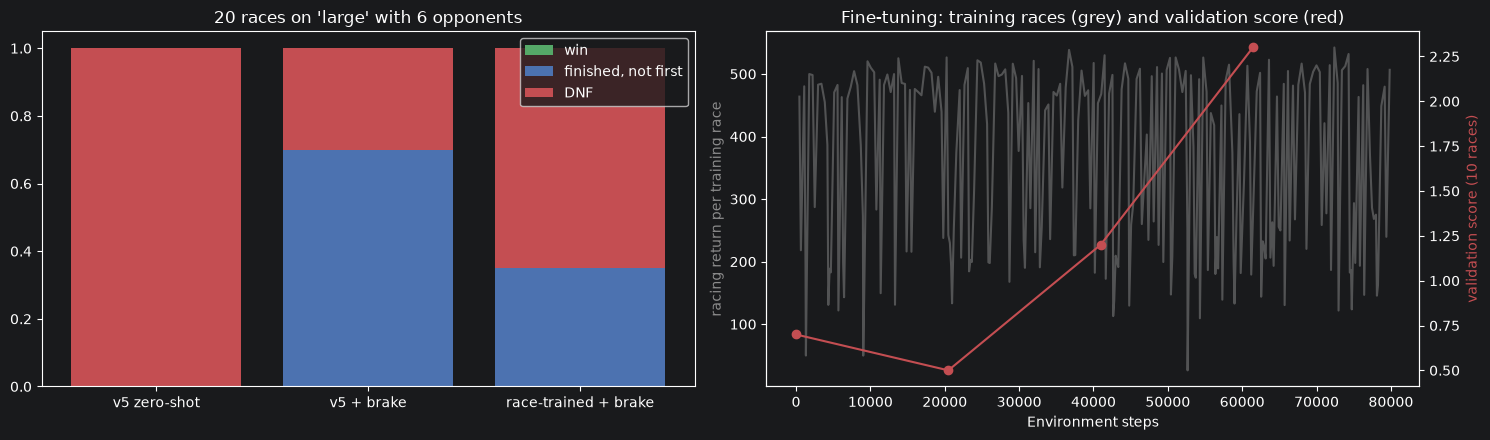

520

In [8]:
# --- BEFORE AND AFTER ---

# The race-trained driver on the same series (with the brake if enabled, as in its training).
if FINE_TUNE:

    # Its name.
    final_label = "race-trained + brake" if SAFETY_BRAKE else "race-trained"

    # Run the series.
    series[final_label] = run_series(make_driver(race_policy), brake=SAFETY_BRAKE)

# Both summaries.
for name, res in series.items():

    # One line each.
    series_summary(name, res)

# Names in order.
names = list(series.keys())

# Two panels.
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Stacked outcomes.
bottom = np.zeros(len(names))

# Three outcomes.
for label, values, colour in [("win", [series[n]["win"].mean() for n in names], "#55A868"),
                              ("finished, not first", [1 - series[n]["win"].mean() - series[n]["dnf"].mean() for n in names], "#4C72B0"),
                              ("DNF", [series[n]["dnf"].mean() for n in names], "#C44E52")]:

    # Bars.
    axes[0].bar(names, values, bottom=bottom, color=colour, label=label)

    # Move the base.
    bottom += np.array(values)

# Title.
axes[0].set_title(f"{SERIES_RACES} races on '{TRACK}' with {N_OPPONENTS} opponents")

# Legend.
axes[0].legend()

# Fine-tuning curve.
if ft_log is not None:

    # Racing return of each training race.
    axes[1].plot(ft_log["steps"], ft_log["return"], color="#8C8C8C", alpha=0.5)

    # y label of the training races.
    axes[1].set_ylabel("racing return per training race", color="#8C8C8C")

    # A second y axis for the validation score (different scale).
    ax_score = axes[1].twinx()

    # Validation score.
    ax_score.plot(ft_log["val_steps"], ft_log["val_score"], marker="o", color="#C44E52")

    # Its label.
    ax_score.set_ylabel("validation score (10 races)", color="#C44E52")

# Title.
axes[1].set_title("Fine-tuning: training races (grey) and validation score (red)")

# x label.
axes[1].set_xlabel("Environment steps")

# Layout.
plt.tight_layout()

# Show.
plt.show()

# Means of every series, saved.
race_results = {"track": TRACK, "opponents": N_OPPONENTS, "race_seconds": RACE_SECONDS,
                "series": {n: {k: float(v.mean()) for k, v in res.items()} for n, res in series.items()}}

# Write.
(RESULTS_DIR / f"race_results_{TRACK}.json").write_text(json.dumps(race_results, indent=2))

## Step 7 — The highlight video

Every frame has two halves:
- **left:** the simulator camera, following our car (green in highway-env's colours);
- **right:** the whole circuit from above, with our car as a large red dot and the opponents as numbered blue dots. On top: the time, our **position**, our lap, the places gained.

At the end a banner shows the result (winner, finishing position, or DNF), held for 2 seconds.

There is one frame per decision (5 per second). The video plays at 10 frames per second (twice real time) or at 5 (`REAL_TIME = True`).

With `HIGHLIGHT_SEED = "best"` the video shows the best race of the final driver's series: a win if there is one, otherwise the race with the best result. Races are deterministic, so the same seed replays exactly the race of the series. The header also shows our **speed**, so you can see when the safety brake acts. The file is saved in `videos/`, ready to share.

Best race of the series for 'race-trained + brake': seed 5002
Race 5002: FINISHED P2 | position 7 -> 2 | 471 frames -> videos/race_large_6cars_seed5002.mp4


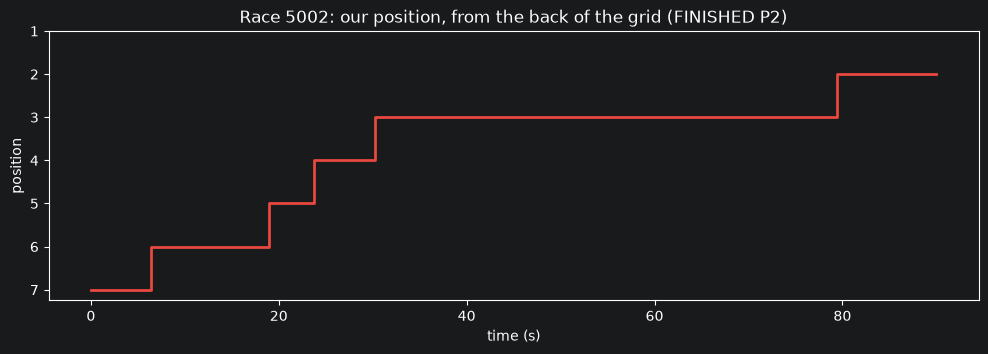

In [9]:
# --- HIGHLIGHT VIDEO ---

# Frames per second of the video.
FPS = 5 if REAL_TIME else 10

# Size of a frame: 12.8 x 6.4 inches at 100 dpi = 1280 x 640 pixels (multiples of 16, as video codecs like).
FIG_SIZE, DPI = (12.8, 6.4), 100


# Draws race frames off-screen.
class RaceFilm:
    """frame(...) stores one picture; frames holds them all."""

    # Figure, axes and the circuit outline.
    def __init__(self, env):

        # Off-screen figure.
        self.fig = Figure(figsize=FIG_SIZE, dpi=DPI, facecolor="#1a1a1a")

        # Its canvas.
        self.canvas = FigureCanvasAgg(self.fig)

        # Left half: the camera.
        self.ax_cam = self.fig.add_axes([0.01, 0.02, 0.48, 0.86])

        # Right half: the map.
        self.ax_map = self.fig.add_axes([0.51, 0.02, 0.48, 0.86])

        # The header text.
        self.header = self.fig.text(0.5, 0.94, "", ha="center", va="center", color="white", fontsize=18, fontweight="bold")

        # All frames.
        self.frames = []

        # Road edges as polylines, computed once per race.
        self.edges = None

    # Compute the edges of every lane of the circuit.
    def outline(self, env):
        """List of (N, 2) arrays."""

        # The road network.
        network = env.unwrapped.road.network

        # Edges.
        edges = []

        # Every segment.
        for start in network.graph:

            # Every end node.
            for end in network.graph[start]:

                # Every lane.
                for lane in network.graph[start][end]:

                    # Points along the lane.
                    s = np.linspace(0, lane.length, 30)

                    # Left and right edges.
                    for side in [-0.5, 0.5]:

                        # Positions of the edge.
                        edges.append(np.array([lane.position(si, side * lane.width_at(si)) for si in s]))

        # Done.
        return edges

    # Draw one frame.
    def frame(self, env, cars, totals, position, step, finished, banner=None):
        """Store the picture of the current moment."""

        # Remember this moment (for the final banner).
        self.last = (env, cars, totals, position, step, finished)

        # First frame of a race: compute the outline.
        if self.edges is None:

            # Road edges.
            self.edges = self.outline(env)

        # Clear the camera half.
        self.ax_cam.clear()

        # The simulator picture.
        self.ax_cam.imshow(env.render())

        # No axes.
        self.ax_cam.axis("off")

        # Clear the map half.
        self.ax_map.clear()

        # Road edges.
        for edge in self.edges:

            # Thin grey line.
            self.ax_map.plot(edge[:, 0], edge[:, 1], color="#777777", linewidth=0.8)

        # Opponents.
        for k, car in enumerate(cars[1:], start=1):

            # Blue dot.
            self.ax_map.plot(*car.position, marker="o", color="#4C9BE8", markersize=9)

            # Its number.
            self.ax_map.text(car.position[0], car.position[1], str(k), color="white", fontsize=7, ha="center", va="center")

        # Our car.
        self.ax_map.plot(*cars[0].position, marker="o", color="#E8483F", markersize=13, markeredgecolor="white")

        # Same scale on both axes.
        self.ax_map.set_aspect("equal")

        # y downwards, as in the simulator.
        self.ax_map.invert_yaxis()

        # No axes.
        self.ax_map.axis("off")

        # Our lap (1-based).
        lap = int(totals[0] // track_lap) + 1

        # Header.
        self.header.set_text(f"t = {step / 5:4.1f} s     POSITION {position} / {len(cars)}     lap {lap}     "
                             f"places gained {len(cars) - position}     speed {cars[0].speed:4.1f} m/s")

        # Final banner over the camera.
        if banner is not None:

            # Big text in the middle of the camera.
            self.ax_cam.text(0.5, 0.5, banner, transform=self.ax_cam.transAxes, ha="center", va="center", fontsize=30,
                             fontweight="bold", color="white", bbox={"facecolor": "black", "alpha": 0.7, "pad": 12})

        # Draw.
        self.canvas.draw()

        # RGB pixels.
        self.frames.append(np.asarray(self.canvas.buffer_rgba())[:, :, :3].copy())

    # Hold the last moment on screen, with a banner.
    def hold(self, banner, n_frames):
        """Redraw the last state once with the banner, then repeat that picture."""

        # Draw it (this appends one frame).
        self.frame(*self.last, banner=banner)

        # Repeat the same picture.
        self.frames.extend([self.frames[-1]] * (n_frames - 1))


# Save frames as MP4 (if possible) or GIF.
def save_video(frames, stem):
    """Return the path of the saved file."""

    # MP4 requested.
    if VIDEO_FORMAT == "mp4":

        # imageio + ffmpeg may be missing.
        try:

            # Video writer.
            import imageio.v2 as imageio

            # Path.
            path = VIDEO_DIR / f"{stem}.mp4"

            # Write the video.
            imageio.mimsave(path, frames, fps=FPS)

            # Done.
            return path

        # Fall back to a GIF.
        except Exception as error:

            # Explain.
            print(f"MP4 not available ({error}). Install it with: pip install imageio imageio-ffmpeg. Saving a GIF instead.")

    # Path of the GIF.
    path = VIDEO_DIR / f"{stem}.gif"

    # Half-size frames, to keep the GIF small.
    images = [PILImage.fromarray(f).resize((f.shape[1] // 2, f.shape[0] // 2)) for f in frames]

    # Save.
    images[0].save(path, save_all=True, append_images=images[1:], duration=int(1000 / FPS), loop=0)

    # Done.
    return path


# Length of a lap on this circuit (used by the header).
track_lap = geo["lap"]

# A new film.
film = RaceFilm(video_env)

# The series of the final driver (the last one computed).
final_name = list(series.keys())[-1]

# Choose the race to film.
if HIGHLIGHT_SEED == "best":

    # Results of the final driver.
    res = series[final_name]

    # Score of each race: a win counts most, then finishing, then places gained.
    score = 100 * res["win"] + 10 * (1 - res["dnf"]) + res["gained"]

    # The best race.
    race_seed = SERIES_SEEDS[int(np.argmax(score))]

    # Report.
    print(f"Best race of the series for '{final_name}': seed {race_seed}")

# A specific race.
else:

    # As given.
    race_seed = HIGHLIGHT_SEED

# The race, with one frame per step (with the safety brake if enabled).
outcome = run_race(make_driver(race_policy), video_env, race_seed, on_step=film.frame, brake=SAFETY_BRAKE)

# The result in words.
if outcome["dnf"]:

    # Crash or off road.
    banner = "DNF - " + ("CRASH" if outcome["crashed"] else "OFF ROAD")

# First place.
elif outcome["win"]:

    # Winner.
    banner = "WINNER!"

# Another place.
else:

    # Ordinal suffix.
    banner = f"FINISHED P{outcome['position']}"

# Hold the final picture with the banner for 2 seconds.
film.hold(banner, 2 * FPS)

# Save the video.
video_path = save_video(film.frames, f"race_{TRACK}_{N_OPPONENTS}cars_seed{race_seed}")

# Report.
print(f"Race {race_seed}: {banner} | position {outcome['positions'][0]} -> {outcome['positions'][-1]} | "
      f"{len(film.frames)} frames -> {video_path}")

# Show it: an MP4 as a video player, a GIF as an image.
if video_path.suffix == ".mp4":

    # Embedded player.
    display(Video(str(video_path), embed=True, width=960))

# GIF.
else:

    # Animated image.
    display(Image(filename=str(video_path)))

# Our position during the race.
fig, ax = plt.subplots(figsize=(12, 3.5))

# Time of each decision.
t = np.arange(len(outcome["positions"])) / 5

# Position over time (a step line).
ax.step(t, outcome["positions"], where="post", color="#E8483F", linewidth=2)

# Position 1 at the top.
ax.invert_yaxis()

# Integer positions only.
ax.set_yticks(range(1, N_OPPONENTS + 2))

# Labels.
ax.set_xlabel("time (s)")

# y label.
ax.set_ylabel("position")

# Title.
ax.set_title(f"Race {race_seed}: our position, from the back of the grid ({banner})")

# Show.
plt.show()

## Results and conclusions

### Three versions of the race
| Version | Change | Best race | What we saw |
|---|---|---|---|
| 1 | v5 driver, opponents at 7–9.5 m/s side by side, 60 s | DNF | A **wall** of cars across all lanes: with no brakes, a crash after 5 s |
| 2 | Staggered grid, slower opponents, 90 s, **safety brake** | **P3**, no crash | 4 places gained in 35 s, then **stuck behind a slow car** for the rest of the race |
| 3 | **Racing reward** (speed + overtakes − crashes), brake also in training | **P2**, no crash | 5 places gained, then again stuck behind the leader, "dancing" left and right behind it |

### The series of the last version (20 races on `large`, 6 opponents)
| Driver | Wins | Mean finishing position | DNF | Places gained | Score |
|---|---|---|---|---|---|
| v5 zero-shot | 0% | – | **100%** | 1.2 | −1.80 |
| v5 + safety brake | 0% | 4.6 of 7 | **30%** | **2.2** | **1.30** |
| race-trained + brake | 0% | 4.7 of 7 | 65% | 2.0 | 0.10 |

### 1. What transferred, and what did not
- **Lane keeping transferred very well.** The v5 driver had seen one circuit with 2 lanes. Here it drove 1.6 laps of a new 3-lane circuit, with hairpins and an S-bend, without leaving the road. Its grid observation is local, so it learned "follow the road I see", not "this circuit".
- **Driving in traffic did not.** Without brakes, the v5 driver crashed in **every** race (100% DNF): v5 never met more than one car, and never several cars side by side.

### 2. The safety brake did most of the work
- A rule of a few lines (slow down if a car is less than 12 m ahead in our path) took the retirements from **100% to 30%**, and the places gained from 1.2 to 2.2.
- This is how real autonomous systems are built: a learned component for the hard perception and decision problems, plus **simple, verifiable safety layers** around it.

### 3. Why the race-trained driver did not learn to overtake
The racing reward changed the behaviour (it gained 5 places in its best race), but on the series it is **worse** than v5 + brake (score 0.10 against 1.30, and 65% DNF). Several reasons work together:
- **The validation chose a lucky checkpoint.** Its best score (2.30 at 61,440 steps) was measured on only 10 races and did not hold on the 20 test races (0.10). The racing return during training even went *down* (460 → 300).
- **Overtaking is a long, risky manoeuvre with a delayed reward.** To earn +2 the car must leave its lane, drive alongside, and come back, over several seconds, risking −5. With 80,000 steps of practice (about 180 races) following the car ahead is the safer bet the agent found.
- **What the agent sees is not enough.** The 12 × 12 grid with 3 m cells shows where the cars are, but not **how fast** they move. It cannot tell if the gap in the next lane is closing or opening. A human overtakes by judging speeds; this agent cannot.
- **It controls only the steering.** It cannot accelerate to pass quickly. The brake slows it down behind the car, and it must change lane *before* it can speed up again.
- **The "dance".** Behind a slow car the policy is in a situation it barely saw in training, and its steering switches between left and right: it starts a lane change and abandons it. This is the nervous steering of v5 (noted in its conclusions), amplified by a situation the policy does not know how to handle.
- **The opponents form a pack.** The IDM cars queue behind the slowest one and fill the other lanes, so free gaps to pass are rare.

### 4. What would be needed to win
None of this is new theory. It is more of what the previous versions taught:
- **A better observation:** the positions **and speeds** of nearby cars, for example the Kinematics observation with the attention network of v4.
- **Throttle and steering** together (as in v6), with the racing reward.
- **Much more training** (millions of steps, not 80,000), possibly with a **curriculum**: 1 opponent, then 2, then 6.
- **More validation races** (at least 30, as we learned in v4), so that model selection is not luck.

### 5. The lesson of the whole race day
**The agent optimises the reward we write, inside the world it can perceive.**
- With the v5 reward it learned to stay in the lane, not to race.
- With the racing reward it learned that following is safer than passing.
- With an observation without speeds it could not judge a gap.

Designing what the agent is rewarded for, and what it can see, matters as much as the learning algorithm.